# SPY Hourly Direction Model: Reproduction and Repair Audit

The original cached experiment is reproduced in sections 1–12; controlled corrections and chronological re-selection are measured in sections 13–14. Sections 15–17 add probability diagnostics, stable selection, feature ablations and policy/execution checks. The data window is **2016-06-28 through 2026-07-10**.

**Corrected historical description:** the saved original calculation reports **33.74% net** for the seven-feature logistic model, **22.80%** for all features, and **27.30%** for buy-and-hold on the final 15%, using its 1-bp turnover assumption. The earlier 43.30% headline did not match these cached outputs and has been removed.

The appended audit uses **zero cost deductions as its base case**, with the original 1-bp assumption shown only as a sensitivity. These are retrospective research comparisons; previously inspected history cannot become a fresh untouched holdout.

## 1. Setup and reproducible configuration

The original reproduction in sections 1–12 needs `polars`, `pyarrow`, NumPy, pandas, scikit-learn and matplotlib. Install missing dependencies into a project environment using `uv pip install`; the optional Alpaca downloader additionally needs `alpaca-py` and environment-provided credentials. The supplied raw and processed snapshots already allow local reproduction without downloading anything.

**For the corrected study, sections 13–14 can run independently:** they include their own imports and use the supplied `spy_hourly_audit.py` with pandas/pyarrow. They require neither Polars nor Alpaca credentials, never download data, and open the original SQLite checkpoint read-only. Generated audit files live under the git-ignored `artifacts/spy_hourly_audit/` directory.

In [3]:
from datetime import date, datetime, time
from pathlib import Path
import hashlib
import itertools
import json
import os
import sqlite3
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from IPython.display import display
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    log_loss,
    mean_squared_error,
    r2_score,
)
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

SYMBOL = 'SPY'
START_DATE = date(2016, 6, 28)
END_DATE = date(2026, 7, 10)
TRADING_HOURS_IN_DAY = 8
TRANSACTION_COST_BPS = 1.0
DOWNLOAD_IF_MISSING = True

STARTING_DIR = Path.cwd()
WORK_DIR = next(
    (candidate for candidate in [STARTING_DIR, *STARTING_DIR.parents]
     if (candidate / 'data' / 'raw' / SYMBOL).is_dir()),
    STARTING_DIR,
)
DATA_DIR = WORK_DIR / 'data'
RAW_DATA_PATH = DATA_DIR / 'raw' / SYMBOL
SNAPSHOT_PATH = RAW_DATA_PATH / f'{SYMBOL}-bars-1h-{START_DATE}_{END_DATE}.parquet'
PROCESSED_DATA_PATH = (
    DATA_DIR / 'processed'
    / f'spy_hourly_feature_target_data_{START_DATE}_{END_DATE}.parquet'
)
SEARCH_DB_PATH = DATA_DIR / 'processed' / 'logistic_feature_search.sqlite'

print(f'Working directory: {WORK_DIR}')
print(f'Pinned window: {START_DATE} through {END_DATE}')
print(f'Download missing data: {DOWNLOAD_IF_MISSING}')

Working directory: /home/deva/Documents/CS 363M/project
Pinned window: 2016-06-28 through 2026-07-10
Download missing data: True


## 2. Download the pinned Alpaca data

Alpaca supplies hourly SIP bars. On a fresh run, the notebook downloads the complete pinned window and writes one local parquet snapshot. The Alpaca import is kept inside the download function, so rerunning from an existing cache does not require `alpaca-py`.

In [4]:
def alpaca_credentials():
    api_key = os.getenv('APCA_API_KEY_ID')
    secret_key = os.getenv('APCA_API_SECRET_KEY')
    if not api_key or not secret_key:
        raise RuntimeError(
            'No compatible local data cache was found. Set APCA_API_KEY_ID and '
            'APCA_API_SECRET_KEY, then rerun this cell to download the pinned data.'
        )
    return api_key, secret_key

def download_pinned_snapshot(output_path):
    try:
        from alpaca.data.enums import DataFeed
        from alpaca.data.historical import StockHistoricalDataClient
        from alpaca.data.requests import StockBarsRequest
        from alpaca.data.timeframe import TimeFrame
    except ModuleNotFoundError as exc:
        raise RuntimeError(
            'alpaca-py is required for a fresh download. Run `%pip install alpaca-py` '
            'and restart the kernel.'
        ) from exc

    api_key, secret_key = alpaca_credentials()
    eastern = ZoneInfo('America/New_York')
    utc = ZoneInfo('UTC')
    request_start = datetime.combine(START_DATE, time(9, 30), eastern).astimezone(utc)
    request_end = datetime.combine(END_DATE, time(16, 0), eastern).astimezone(utc)
    request = StockBarsRequest(
        symbol_or_symbols=SYMBOL,
        start=request_start,
        end=request_end,
        timeframe=TimeFrame.Hour,
        feed=DataFeed.SIP,
    )
    print(f'Downloading {SYMBOL} hourly SIP bars from {START_DATE} through {END_DATE}...')
    downloaded = StockHistoricalDataClient(api_key, secret_key).get_stock_bars(request).df
    downloaded = downloaded.reset_index()
    downloaded = downloaded.rename(columns={
        'timestamp': 'datetime', 'vwap': 'mean_price', 'n': 'trade_count'
    })
    if 'symbol' in downloaded.columns:
        downloaded = downloaded.loc[downloaded['symbol'] == SYMBOL]
    if downloaded.empty:
        raise RuntimeError('Alpaca returned no bars for the pinned request.')

    bars = pl.from_pandas(downloaded).with_columns(
        pl.col('datetime').cast(pl.Datetime(time_zone='UTC')),
        pl.col('open').cast(pl.Float64),
        pl.col('high').cast(pl.Float64),
        pl.col('low').cast(pl.Float64),
        pl.col('close').cast(pl.Float64),
        pl.col('volume').cast(pl.Float64),
        pl.col('trade_count').cast(pl.Int64),
        pl.col('mean_price').cast(pl.Float64),
    ).with_columns(
        (pl.col('mean_price') * pl.col('volume')).alias('dollar_volume')
    ).select(
        'symbol', 'datetime', 'open', 'high', 'low', 'close', 'volume',
        'trade_count', 'mean_price', 'dollar_volume',
    ).sort('datetime')
    output_path.parent.mkdir(parents=True, exist_ok=True)
    bars.write_parquet(output_path)
    print(f'Wrote {bars.height:,} hourly bars to {output_path}')
    return output_path

if SNAPSHOT_PATH.exists():
    raw_bar_paths = [SNAPSHOT_PATH]
    print(f'Using pinned snapshot: {SNAPSHOT_PATH}')
elif DOWNLOAD_IF_MISSING:
    raw_bar_paths = [download_pinned_snapshot(SNAPSHOT_PATH)]
else:
    raise FileNotFoundError(
        f'No complete pinned cache found under {RAW_DATA_PATH}. '
        'Enable DOWNLOAD_IF_MISSING or provide the snapshot.'
    )

Wrote 39,682 hourly bars to /home/deva/Documents/CS 363M/project/data/raw/SPY/SPY-bars-1h-2016-06-28_2026-07-10.parquet


## 3. Read and validate hourly bars

The cached hourly bars are normalized directly in this notebook. Only observations inside the pinned window are retained, so later files cannot alter the split boundaries or model result.

In [5]:
intraday_bars = (
    pl.scan_parquet([str(path) for path in raw_bar_paths])
    .select(
        pl.col('symbol'),
        pl.col('datetime').cast(pl.Datetime(time_zone='UTC')),
        pl.col('open').cast(pl.Float64),
        pl.col('high').cast(pl.Float64),
        pl.col('low').cast(pl.Float64),
        pl.col('close').cast(pl.Float64),
        pl.col('volume').cast(pl.Float64),
        pl.col('trade_count').cast(pl.Int64),
        pl.col('mean_price').cast(pl.Float64),
        pl.col('dollar_volume').cast(pl.Float64),
    )
    .filter(pl.col('datetime').dt.date().is_between(START_DATE, END_DATE, closed='both'))
    .collect()
    .with_columns(
        pl.col('datetime').dt.date().alias('date'),
    )
    .select(
        'symbol', 'date', 'datetime', 'open', 'high', 'low', 'close',
        'volume', 'dollar_volume', 'trade_count', 'mean_price',
    )
    .sort('datetime')
)

raw_summary = intraday_bars.select(
    pl.len().alias('rows'),
    pl.col('datetime').min().alias('first_bar'),
    pl.col('datetime').max().alias('last_bar'),
    pl.col('date').n_unique().alias('trading_days'),
    pl.col('close').null_count().alias('null_closes'),
)
duplicate_timestamps = intraday_bars.height - intraday_bars.get_column('datetime').n_unique()
display(raw_summary)
print(f'Duplicate hourly timestamps: {duplicate_timestamps}')
display(intraday_bars.head(10))

rows,first_bar,last_bar,trading_days,null_closes
u32,"datetime[μs, UTC]","datetime[μs, UTC]",u32,u32
39682,2016-06-28 14:00:00 UTC,2026-07-10 20:00:00 UTC,2592,0


Duplicate hourly timestamps: 0


symbol,date,datetime,open,high,low,close,volume,dollar_volume,trade_count,mean_price
str,date,"datetime[μs, UTC]",f64,f64,f64,f64,f64,f64,i64,f64
"""SPY""",2016-06-28,2016-06-28 14:00:00 UTC,202.13,202.3,201.51,201.61,2.3102224e7,4.6636e9,99284,201.867639
"""SPY""",2016-06-28,2016-06-28 15:00:00 UTC,201.61,201.89,201.12,201.8135,1.7410279e7,3.5078e9,78489,201.479122
"""SPY""",2016-06-28,2016-06-28 16:00:00 UTC,201.82,202.11,201.54,201.9198,1.1985726e7,2.4188e9,46286,201.810195
"""SPY""",2016-06-28,2016-06-28 17:00:00 UTC,201.91,201.95,201.38,201.65,1.2254064e7,2.4713e9,46248,201.67192
"""SPY""",2016-06-28,2016-06-28 18:00:00 UTC,201.65,202.97,201.35,202.75,1.8995769e7,3.8392e9,72329,202.107164
"""SPY""",2016-06-28,2016-06-28 19:00:00 UTC,202.74,203.2,202.37,203.1725,3.5921169e7,7.2872e9,139071,202.867807
"""SPY""",2016-06-28,2016-06-28 20:00:00 UTC,203.17,203.47,203.11,203.32,1.4156163e7,2.8769e9,6276,203.226273
"""SPY""",2016-06-28,2016-06-28 21:00:00 UTC,203.3,204.3308,201.9191,203.3,1.115249e6,2.2651e8,238,203.100223
"""SPY""",2016-06-28,2016-06-28 22:00:00 UTC,203.3,203.32,203.06,203.27,84348.0,1.7137e7,258,203.168786


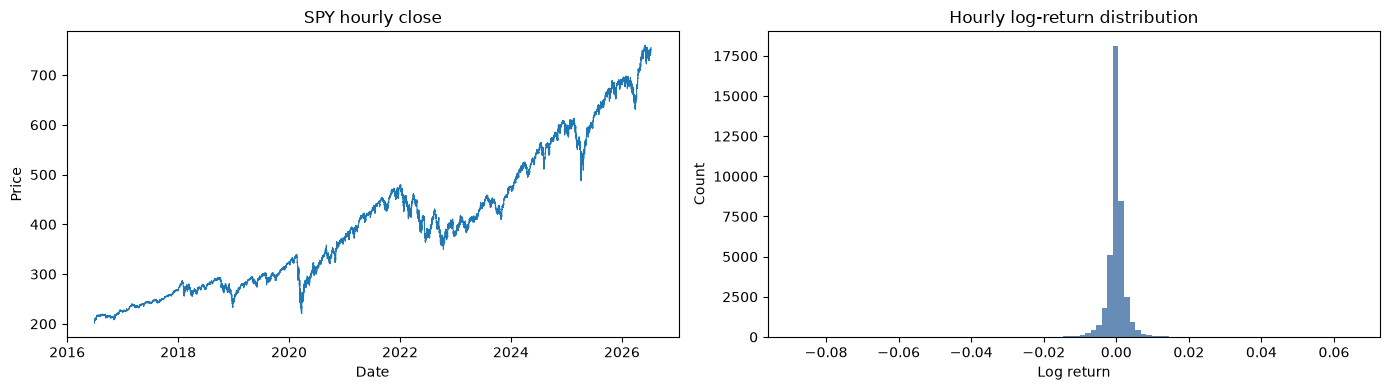

In [6]:
if not intraday_bars.get_column('datetime').is_sorted():
    raise ValueError('Hourly bars are not in chronological order.')
if duplicate_timestamps:
    raise ValueError(f'Found {duplicate_timestamps} duplicate hourly timestamps.')
if intraday_bars.get_column('close').null_count():
    raise ValueError('Close prices contain null values.')

hourly_returns_for_plot = intraday_bars.select(
    pl.col('datetime'),
    (pl.col('close') / pl.col('close').shift(1)).log().alias('log_return'),
).drop_nulls()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(intraday_bars['datetime'], intraday_bars['close'], linewidth=0.8)
axes[0].set(title='SPY hourly close', xlabel='Date', ylabel='Price')
axes[1].hist(hourly_returns_for_plot['log_return'], bins=100, color='#4c78a8', alpha=0.85)
axes[1].set(title='Hourly log-return distribution', xlabel='Log return', ylabel='Count')
plt.tight_layout()
plt.show()

## 4. Feature engineering

The target is bar `t`'s close-to-close log return. Every predictor is shifted or constructed from shifted prices, so it uses information available through bar `t-1`. The model receives 14 candidate features: trend distance, Bollinger position, PGO, two rolling return averages, and eight individual return lags.

In [7]:
data = (
    intraday_bars.sort('datetime')
    .with_columns(
        pl.col('close').diff().alias('price_delta'),
        (pl.col('close') / pl.col('close').shift(1)).log().alias('log_return'),
        pl.col('close').shift(1).rolling_mean(TRADING_HOURS_IN_DAY * 10).alias('close_ma_10d'),
    )
    .with_columns(
        pl.col('price_delta').shift(1).alias('price_delta_lag_1'),
        (pl.col('close_ma_10d') - pl.col('close').shift(1)).alias('price_delta_w_ma_10d'),
    )
)

BOLLINGER_PERIOD = TRADING_HOURS_IN_DAY
BOLLINGER_STD_MULTIPLIER = 2
bollinger_close = pl.col('close').shift(1)
bollinger_mean = bollinger_close.rolling_mean(BOLLINGER_PERIOD)
bollinger_std = bollinger_close.rolling_std(BOLLINGER_PERIOD, ddof=0)
upper_band = bollinger_mean + BOLLINGER_STD_MULTIPLIER * bollinger_std
lower_band = bollinger_mean - BOLLINGER_STD_MULTIPLIER * bollinger_std

data = data.with_columns(
    ((bollinger_close - upper_band) / upper_band).alias('close_relative_to_upper_band'),
    ((bollinger_close - lower_band) / lower_band).alias('close_relative_to_lower_band'),
)

PGO_PERIOD = TRADING_HOURS_IN_DAY
pgo_close = pl.col('close').shift(1)
pgo_high = pl.col('high').shift(1)
pgo_low = pl.col('low').shift(1)
pgo_previous_close = pl.col('close').shift(2)
true_range = pl.max_horizontal(
    pgo_high - pgo_low,
    (pgo_high - pgo_previous_close).abs(),
    (pgo_low - pgo_previous_close).abs(),
)
pgo_close_mean = pgo_close.rolling_mean(PGO_PERIOD)
pgo_atr_mean = true_range.rolling_mean(PGO_PERIOD).rolling_mean(PGO_PERIOD)
data = data.with_columns(
    ((pgo_close - pgo_close_mean) / pgo_atr_mean).alias(f'PGO_{PGO_PERIOD}')
)

In [8]:
for lag in range(1, 9):
    data = data.with_columns(
        pl.col('log_return').shift(lag).alias(f'log_return_lag_{lag}')
    )

data = data.with_columns(
    pl.col('log_return_lag_1')
    .rolling_mean(TRADING_HOURS_IN_DAY)
    .alias('log_return_ma_1d_lag_1'),
    pl.col('log_return_lag_1')
    .rolling_mean(TRADING_HOURS_IN_DAY * 10)
    .alias('log_return_ma_10d_lag_1'),
)

features = [
    'price_delta_w_ma_10d',
    'close_relative_to_upper_band',
    'close_relative_to_lower_band',
    f'PGO_{PGO_PERIOD}',
    'log_return_ma_1d_lag_1',
    'log_return_ma_10d_lag_1',
] + [f'log_return_lag_{lag}' for lag in range(1, 9)]
target = 'log_return'

final_data_with_time = data.select('datetime', *features, target).drop_nulls()
final_data = final_data_with_time.select(*features, target)

feature_catalog = pd.DataFrame({
    'feature': features,
    'information_available': ['through t-1'] * len(features),
})
display(feature_catalog)
display(final_data_with_time.head())

,feature,information_available
0,price_delta_w_ma_10d,through t-1
1,close_relative_to_upper_band,through t-1
2,close_relative_to_lower_band,through t-1
3,PGO_8,through t-1
4,log_return_ma_1d_lag_1,through t-1
5,log_return_ma_10d_lag_1,through t-1
6,log_return_lag_1,through t-1
7,log_return_lag_2,through t-1
8,log_return_lag_3,through t-1
9,log_return_lag_4,through t-1


datetime,price_delta_w_ma_10d,close_relative_to_upper_band,close_relative_to_lower_band,PGO_8,log_return_ma_1d_lag_1,log_return_ma_10d_lag_1,log_return_lag_1,log_return_lag_2,log_return_lag_3,log_return_lag_4,log_return_lag_5,log_return_lag_6,log_return_lag_7,log_return_lag_8,log_return
"datetime[μs, UTC]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2016-07-06 17:00:00 UTC,-1.86303,0.000057,0.01241,1.928445,0.000923,0.000468,0.002775,0.002878,0.002117,0.000482,0.000626,0.000579,-0.002794,0.000722,-0.0011
2016-07-06 18:00:00 UTC,-1.542324,-0.002556,0.011433,1.324266,0.000695,0.000442,-0.0011,0.002775,0.002878,0.002117,0.000482,0.000626,0.000579,-0.002794,0.002436
2016-07-06 19:00:00 UTC,-1.956571,-0.002024,0.0131,1.601749,0.001349,0.000465,0.002436,-0.0011,0.002775,0.002878,0.002117,0.000482,0.000626,0.000579,0.000811
2016-07-06 20:00:00 UTC,-2.025321,-0.002645,0.012581,1.383672,0.001378,0.000492,0.000811,0.002436,-0.0011,0.002775,0.002878,0.002117,0.000482,0.000626,-0.000143
2016-07-06 21:00:00 UTC,-1.908196,-0.003353,0.010409,0.946633,0.001282,0.000422,-0.000143,0.000811,0.002436,-0.0011,0.002775,0.002878,0.002117,0.000482,0.0


## 5. Persist and verify the model-ready dataset

Saving the exact feature matrix makes the model experiment auditable without repeating the download and aggregation stages. The timestamp is retained in memory for split reporting but excluded from the model matrix.

In [9]:
PROCESSED_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
final_data.write_parquet(PROCESSED_DATA_PATH)
persisted_data = pl.read_parquet(PROCESSED_DATA_PATH)
if not persisted_data.equals(final_data):
    raise ValueError('Persisted feature data does not match the in-memory frame.')

dataset_summary = final_data_with_time.select(
    pl.len().alias('usable_rows'),
    pl.col('datetime').min().alias('first_usable_bar'),
    pl.col('datetime').max().alias('last_usable_bar'),
    pl.col(target).mean().alias('mean_log_return'),
    pl.col(target).std().alias('return_std'),
    (pl.col(target) > 0).mean().alias('positive_bar_rate'),
)
display(dataset_summary)
print(f'Features: {len(features)}')
print(f'Wrote verified dataset to: {PROCESSED_DATA_PATH}')

usable_rows,first_usable_bar,last_usable_bar,mean_log_return,return_std,positive_bar_rate
u32,"datetime[μs, UTC]","datetime[μs, UTC]",f64,f64,f64
39601,2016-07-06 17:00:00 UTC,2026-07-10 20:00:00 UTC,0.000032,0.002838,0.521502


Features: 14
Wrote verified dataset to: /home/deva/Documents/CS 363M/project/data/processed/spy_hourly_feature_target_data_2016-06-28_2026-07-10.parquet


## 6. Original baseline experiments

These baselines reproduce the exploratory 80/20 chronological split from the original notebook. They compare continuous-return regression, direction classification, and a small decision tree. This section uses zero trading cost, as the original baseline table did, and is therefore kept separate from the final fair comparison.

This 80/20 exploratory test overlaps the later final 15%. It therefore invalidates a claim that the later period was never inspected, even though the feature-search fitting code does not train on that final period.

In [10]:
X_baseline = final_data.select(features).to_numpy().astype(np.float64)
y_baseline = final_data.get_column(target).to_numpy().astype(np.float64)
baseline_split_idx = int(len(final_data) * 0.80)

X_train_raw, X_test_raw = X_baseline[:baseline_split_idx], X_baseline[baseline_split_idx:]
y_train, y_test = y_baseline[:baseline_split_idx], y_baseline[baseline_split_idx:]
baseline_scaler = StandardScaler()
X_train = baseline_scaler.fit_transform(X_train_raw)
X_test = baseline_scaler.transform(X_test_raw)

linear_baseline = LinearRegression().fit(X_train, y_train)
linear_test_pred = linear_baseline.predict(X_test)

y_train_direction = (y_train > 0).astype(np.int8)
y_test_direction = (y_test > 0).astype(np.int8)
logistic_baseline = LogisticRegression(max_iter=1_000, random_state=RANDOM_SEED)
logistic_baseline.fit(X_train, y_train_direction)
logistic_test_prob = logistic_baseline.predict_proba(X_test)[:, 1]
logistic_test_pred = (logistic_test_prob >= 0.5).astype(np.int8)

decision_tree_baseline = DecisionTreeRegressor(
    max_depth=5, min_samples_leaf=100, random_state=RANDOM_SEED
)
decision_tree_baseline.fit(X_train_raw, y_train)
decision_tree_test_pred = decision_tree_baseline.predict(X_test_raw)

print(f'Linear MSE: {mean_squared_error(y_test, linear_test_pred):.10f}')
print(f'Linear R²: {r2_score(y_test, linear_test_pred):.6f}')
print(f'Linear direction accuracy: {np.mean((linear_test_pred > 0) == (y_test > 0)):.2%}')
print()
print(f'Logistic log loss: {log_loss(y_test_direction, logistic_test_prob):.6f}')
print(f'Logistic direction accuracy: {accuracy_score(y_test_direction, logistic_test_pred):.2%}')
print(f'Logistic prediction counts: {dict(zip(*np.unique(logistic_test_pred, return_counts=True)))}')
print()
print(f'Decision-tree MSE: {mean_squared_error(y_test, decision_tree_test_pred):.10f}')
print(f'Decision-tree R²: {r2_score(y_test, decision_tree_test_pred):.6f}')
print(f'Decision-tree direction accuracy: {np.mean((decision_tree_test_pred > 0) == (y_test > 0)):.2%}')

Linear MSE: 0.0000070858
Linear R²: -0.008655
Linear direction accuracy: 49.84%

Logistic log loss: 0.692098
Logistic direction accuracy: 52.25%
Logistic prediction counts: {np.int8(0): np.int64(136), np.int8(1): np.int64(7785)}

Decision-tree MSE: 0.0000071515
Decision-tree R²: -0.018016
Decision-tree direction accuracy: 52.38%


In [11]:
BARS_PER_YEAR = 252 * TRADING_HOURS_IN_DAY

def baseline_strategy_statistics(name, position):
    returns = position * y_test
    equity = np.exp(np.cumsum(returns))
    drawdown = equity / np.maximum.accumulate(equity) - 1.0
    return_std = returns.std(ddof=1)
    return {
        'model': name,
        'direction_accuracy': np.mean((position > 0) == (y_test > 0)),
        'net_return': equity[-1] - 1.0,
        'annualized_sharpe': (returns.mean() / return_std * np.sqrt(BARS_PER_YEAR)),
        'max_drawdown': drawdown.min(),
        'hit_rate': np.mean(returns > 0),
        'long_rate': np.mean(position > 0),
        'position_changes': np.count_nonzero(np.diff(position)),
    }

baseline_positions = {
    'Buy and hold': np.ones_like(y_test),
    'Linear regression': np.where(linear_test_pred > 0, 1.0, -1.0),
    'Logistic regression': np.where(logistic_test_pred == 1, 1.0, -1.0),
    'Decision tree': np.where(decision_tree_test_pred > 0, 1.0, -1.0),
}
baseline_stats = pd.DataFrame([
    baseline_strategy_statistics(name, position)
    for name, position in baseline_positions.items()
])
display(baseline_stats)

coefficient_table = pd.DataFrame({
    'feature': features,
    'linear_coefficient': linear_baseline.coef_,
    'logistic_coefficient': logistic_baseline.coef_[0],
}).sort_values('logistic_coefficient', key=np.abs, ascending=False)
display(coefficient_table)

,model,direction_accuracy,net_return,annualized_sharpe,max_drawdown,hit_rate,long_rate,position_changes
0,Buy and hold,0.523798,0.364490,0.664615,-0.204531,0.523798,1.000000,0
1,Linear regression,0.498422,0.130129,0.261586,-0.169654,0.496654,0.578967,3788
2,Logistic regression,0.522535,0.450288,0.795063,-0.178436,0.522535,0.982830,184
3,Decision tree,0.523798,0.172980,0.341171,-0.286266,0.523798,0.997223,36


,feature,linear_coefficient,logistic_coefficient
0,price_delta_w_ma_10d,0.000012,0.016181
9,log_return_lag_4,0.000475,0.014638
3,PGO_8,0.000197,-0.013075
11,log_return_lag_6,-0.000007,-0.012166
13,log_return_lag_8,-0.000316,0.012018
2,close_relative_to_lower_band,-0.001788,-0.011206
1,close_relative_to_upper_band,-0.001979,0.005879
4,log_return_ma_1d_lag_1,0.000967,0.004198
7,log_return_lag_2,0.000896,-0.003845
5,log_return_ma_10d_lag_1,0.000020,0.003250


## 7. Exhaustive logistic-regression feature search

For the principal experiment, the first 70% of observations train each candidate, the next 15% select the feature subset, and the final 15% is excluded from fitting and subset ranking within this search. That period had already been evaluated by the earlier 80/20 baseline, so it is not a pristine holdout. All **16,383** nonempty subsets of the 14 features are tested. Candidates are ranked by validation net return after one basis point per unit of turnover.

Results are checkpointed in SQLite. A hash of the data and configuration prevents results from a different experiment from being mixed into this run.

In [12]:
X_feature_search = final_data.select(features).to_numpy().astype(np.float64)
y_feature_search = final_data.get_column(target).to_numpy().astype(np.float64)
feature_search_train_end = int(len(y_feature_search) * 0.70)
feature_search_validation_end = int(len(y_feature_search) * 0.85)

X_feature_train = X_feature_search[:feature_search_train_end]
y_feature_train = y_feature_search[:feature_search_train_end]
X_feature_validation = X_feature_search[feature_search_train_end:feature_search_validation_end]
y_feature_validation = y_feature_search[feature_search_train_end:feature_search_validation_end]
X_feature_test = X_feature_search[feature_search_validation_end:]
y_feature_test = y_feature_search[feature_search_validation_end:]

split_summary = pd.DataFrame([
    {
        'split': 'train', 'rows': feature_search_train_end,
        'start': final_data_with_time[0, 'datetime'],
        'end': final_data_with_time[feature_search_train_end - 1, 'datetime'],
    },
    {
        'split': 'validation',
        'rows': feature_search_validation_end - feature_search_train_end,
        'start': final_data_with_time[feature_search_train_end, 'datetime'],
        'end': final_data_with_time[feature_search_validation_end - 1, 'datetime'],
    },
    {
        'split': 'final test', 'rows': len(y_feature_test),
        'start': final_data_with_time[feature_search_validation_end, 'datetime'],
        'end': final_data_with_time[-1, 'datetime'],
    },
])
display(split_summary)

,split,rows,start,end
0,train,27720,2016-07-06 17:00:00+00:00,2023-07-24 23:00:00+00:00
1,validation,5940,2023-07-25 08:00:00+00:00,2025-01-15 19:00:00+00:00
2,final test,5941,2025-01-15 20:00:00+00:00,2026-07-10 20:00:00+00:00


In [13]:
feature_search_cost = TRANSACTION_COST_BPS / 10_000.0

def strategy_metrics(predictions, realized_log_returns):
    positions = np.where(np.asarray(predictions) == 1, 1.0, -1.0)
    turnover_by_bar = np.abs(np.diff(positions, prepend=0.0))
    gross_log_returns = positions * np.asarray(realized_log_returns)
    net_log_returns = gross_log_returns - turnover_by_bar * feature_search_cost
    return {
        'net_return': float(np.exp(net_log_returns.sum()) - 1.0),
        'gross_return': float(np.exp(gross_log_returns.sum()) - 1.0),
        'position_changes': int(np.count_nonzero(np.diff(positions))),
        'turnover': float(turnover_by_bar.sum()),
        'long_rate': float(np.mean(positions > 0)),
    }

data_hasher = hashlib.sha256()
data_hasher.update(X_feature_search.tobytes())
data_hasher.update(y_feature_search.tobytes())
search_config = json.dumps({
    'features': features,
    'cost_bps': TRANSACTION_COST_BPS,
    'train_end': feature_search_train_end,
    'validation_end': feature_search_validation_end,
    'data_hash': data_hasher.hexdigest(),
}, sort_keys=True)
search_id = hashlib.sha256(search_config.encode()).hexdigest()

SEARCH_DB_PATH.parent.mkdir(parents=True, exist_ok=True)
with sqlite3.connect(SEARCH_DB_PATH) as search_db:
    search_db.execute('''
        CREATE TABLE IF NOT EXISTS feature_search_results (
            search_id TEXT NOT NULL,
            feature_key TEXT NOT NULL,
            features_json TEXT NOT NULL,
            feature_count INTEGER NOT NULL,
            net_return REAL NOT NULL,
            gross_return REAL NOT NULL,
            position_changes INTEGER NOT NULL,
            turnover REAL NOT NULL,
            long_rate REAL NOT NULL,
            PRIMARY KEY (search_id, feature_key)
        )
    ''')
    completed_feature_keys = {
        row[0] for row in search_db.execute(
            'SELECT feature_key FROM feature_search_results WHERE search_id = ?',
            (search_id,),
        )
    }
    total_feature_subsets = 2 ** len(features) - 1
    print(f'Resuming with {len(completed_feature_keys):,}/{total_feature_subsets:,} combinations complete.')

    for subset_size in range(1, len(features) + 1):
        print(f'Testing feature subsets of size {subset_size}...')
        for feature_subset in itertools.combinations(features, subset_size):
            feature_key = json.dumps(list(feature_subset), separators=(',', ':'))
            if feature_key in completed_feature_keys:
                continue
            indices = [features.index(name) for name in feature_subset]
            scaler = StandardScaler()
            X_train_subset = scaler.fit_transform(X_feature_train[:, indices])
            X_validation_subset = scaler.transform(X_feature_validation[:, indices])
            model = LogisticRegression(max_iter=1_000, random_state=RANDOM_SEED)
            model.fit(X_train_subset, (y_feature_train > 0).astype(np.int8))
            validation_predictions = model.predict(X_validation_subset)
            metrics = strategy_metrics(validation_predictions, y_feature_validation)
            search_db.execute(
                'INSERT OR REPLACE INTO feature_search_results VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?)',
                (
                    search_id, feature_key, json.dumps(list(feature_subset)), len(feature_subset),
                    metrics['net_return'], metrics['gross_return'],
                    metrics['position_changes'], metrics['turnover'], metrics['long_rate'],
                ),
            )
            search_db.commit()
            completed_feature_keys.add(feature_key)

    feature_search_results_df = pd.read_sql_query(
        'SELECT * FROM feature_search_results WHERE search_id = ?',
        search_db, params=(search_id,),
    )

feature_search_results_df = (
    feature_search_results_df
    .assign(features=lambda frame: frame['features_json'].map(lambda value: tuple(json.loads(value))))
    .sort_values('net_return', ascending=False)
    .reset_index(drop=True)
)
print(f'Search complete. Checkpoint: {SEARCH_DB_PATH}')
display(feature_search_results_df.head(20))

Resuming with 0/16,383 combinations complete.
Testing feature subsets of size 1...
Testing feature subsets of size 2...
Testing feature subsets of size 3...
Testing feature subsets of size 4...
Testing feature subsets of size 5...
Testing feature subsets of size 6...
Testing feature subsets of size 7...
Testing feature subsets of size 8...
Testing feature subsets of size 9...
Testing feature subsets of size 10...
Testing feature subsets of size 11...
Testing feature subsets of size 12...
Testing feature subsets of size 13...
Testing feature subsets of size 14...
Search complete. Checkpoint: /home/deva/Documents/CS 363M/project/data/processed/logistic_feature_search.sqlite


,search_id,feature_key,features_json,feature_count,net_return,gross_return,position_changes,turnover,long_rate,features
0,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""close_relativ...","[""close_relative_to_upper_band"", ""close_relati...",7,0.409810,0.420708,38,77.0,0.995791,"(close_relative_to_upper_band, close_relative_..."
1,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""PGO_8"",""log_r...","[""close_relative_to_upper_band"", ""PGO_8"", ""log...",7,0.406456,0.418461,42,85.0,0.995118,"(close_relative_to_upper_band, PGO_8, log_retu..."
2,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""PGO_8"",""log_r...","[""close_relative_to_upper_band"", ""PGO_8"", ""log...",7,0.403430,0.414844,40,81.0,0.995455,"(close_relative_to_upper_band, PGO_8, log_retu..."
3,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""close_relativ...","[""close_relative_to_upper_band"", ""close_relati...",7,0.402514,0.413920,40,81.0,0.995286,"(close_relative_to_upper_band, close_relative_..."
4,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""PGO_8"",""log_r...","[""close_relative_to_upper_band"", ""PGO_8"", ""log...",8,0.402198,0.415300,46,93.0,0.994949,"(close_relative_to_upper_band, PGO_8, log_retu..."
5,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""PGO_8"",""log_r...","[""close_relative_to_upper_band"", ""PGO_8"", ""log...",7,0.402198,0.415300,46,93.0,0.994949,"(close_relative_to_upper_band, PGO_8, log_retu..."
6,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""PGO_8"",""log_r...","[""close_relative_to_upper_band"", ""PGO_8"", ""log...",6,0.402127,0.414096,42,85.0,0.995286,"(close_relative_to_upper_band, PGO_8, log_retu..."
7,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""close_relativ...","[""close_relative_to_upper_band"", ""close_relati...",9,0.401779,0.412614,38,77.0,0.995791,"(close_relative_to_upper_band, close_relative_..."
8,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""close_relativ...","[""close_relative_to_upper_band"", ""close_relati...",8,0.400766,0.411029,36,73.0,0.996128,"(close_relative_to_upper_band, close_relative_..."
9,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""close_relativ...","[""close_relative_to_upper_band"", ""close_relati...",8,0.399972,0.412488,44,89.0,0.995118,"(close_relative_to_upper_band, close_relative_..."


## 8. Refit and evaluate the validation-selected model

The winning subset is chosen from validation performance, refitted on the first 85%, and evaluated on the final 15%. This is a retrospective comparison because earlier exploratory baselines already inspected an overlapping test window.

In [14]:
best_features = list(feature_search_results_df.iloc[0]['features'])
best_feature_indices = [features.index(name) for name in best_features]
X_development_selected = X_feature_search[:feature_search_validation_end, best_feature_indices]
y_development = y_feature_search[:feature_search_validation_end]
X_final_test_selected = X_feature_test[:, best_feature_indices]

selected_scaler = StandardScaler()
X_development_selected_scaled = selected_scaler.fit_transform(X_development_selected)
X_final_test_selected_scaled = selected_scaler.transform(X_final_test_selected)
selected_model = LogisticRegression(max_iter=1_000, random_state=RANDOM_SEED)
selected_model.fit(
    X_development_selected_scaled,
    (y_development > 0).astype(np.int8),
)
selected_test_probabilities = selected_model.predict_proba(X_final_test_selected_scaled)[:, 1]
selected_test_predictions = (selected_test_probabilities >= 0.5).astype(np.int8)
selected_test_metrics = strategy_metrics(selected_test_predictions, y_feature_test)

print('Best validation feature combination:')
for feature in best_features:
    print(f'  {feature}')
print(f"Validation net return: {feature_search_results_df.iloc[0]['net_return']:.2%}")
print(f"Final-test net return: {selected_test_metrics['net_return']:.2%}")
print(f"Final-test gross return: {selected_test_metrics['gross_return']:.2%}")
print(f"Direction accuracy: {accuracy_score(y_feature_test > 0, selected_test_predictions):.2%}")
print(f"Position changes: {selected_test_metrics['position_changes']}")
print(f"Long rate: {selected_test_metrics['long_rate']:.2%}")

Best validation feature combination:
  close_relative_to_upper_band
  close_relative_to_lower_band
  PGO_8
  log_return_ma_1d_lag_1
  log_return_lag_3
  log_return_lag_4
  log_return_lag_8
Validation net return: 40.98%
Final-test net return: 33.74%
Final-test gross return: 36.18%
Direction accuracy: 52.35%
Position changes: 90
Long rate: 99.04%


## 9. Historical all-feature logistic comparison

The all-feature model uses the same development observations, standardization, 0.50 threshold, final-test window and legacy transaction-cost function as the selected-feature model. The current saved output is 22.80% net; the previous 43% narrative referred to a different result and is not supported by this cached run.

In [15]:
all_feature_scaler = StandardScaler()
X_development_all = all_feature_scaler.fit_transform(
    X_feature_search[:feature_search_validation_end]
)
X_final_test_all = all_feature_scaler.transform(X_feature_test)
all_feature_model = LogisticRegression(max_iter=1_000, random_state=RANDOM_SEED)
all_feature_model.fit(
    X_development_all,
    (y_feature_search[:feature_search_validation_end] > 0).astype(np.int8),
)
all_feature_test_probabilities = all_feature_model.predict_proba(X_final_test_all)[:, 1]
all_feature_test_predictions = (all_feature_test_probabilities >= 0.5).astype(np.int8)
all_feature_test_metrics = strategy_metrics(all_feature_test_predictions, y_feature_test)

print(f"All-feature final-test net return: {all_feature_test_metrics['net_return']:.2%}")
print(f"All-feature final-test gross return: {all_feature_test_metrics['gross_return']:.2%}")
print(f"Direction accuracy: {accuracy_score(y_feature_test > 0, all_feature_test_predictions):.2%}")
print(f"Log loss: {log_loss(y_feature_test > 0, all_feature_test_probabilities):.6f}")
print(f"Position changes: {all_feature_test_metrics['position_changes']}")
print(f"Long rate: {all_feature_test_metrics['long_rate']:.2%}")

all_feature_coefficients = pd.DataFrame({
    'feature': features,
    'standardized_coefficient': all_feature_model.coef_[0],
}).sort_values('standardized_coefficient', key=np.abs, ascending=False)
display(all_feature_coefficients)

All-feature final-test net return: 22.80%
All-feature final-test gross return: 25.74%
Direction accuracy: 52.25%
Log loss: 0.692075
Position changes: 118
Long rate: 98.80%


,feature,standardized_coefficient
9,log_return_lag_4,0.014819
3,PGO_8,-0.013385
13,log_return_lag_8,0.013337
11,log_return_lag_6,-0.011718
2,close_relative_to_lower_band,-0.010167
0,price_delta_w_ma_10d,0.006463
1,close_relative_to_upper_band,0.005366
5,log_return_ma_10d_lag_1,-0.003718
4,log_return_ma_1d_lag_1,0.003485
7,log_return_lag_2,-0.002778


## 10. Fair final-test comparison

Every strategy below uses the same final 15%, compounds the same hourly log returns, and pays one basis point per position unit. A long-to-short reversal has two units of turnover and therefore costs two basis points.

In [16]:
buy_hold_predictions = np.ones(len(y_feature_test), dtype=np.int8)
buy_hold_metrics = strategy_metrics(buy_hold_predictions, y_feature_test)
fair_final_test_comparison = pd.DataFrame([
    {
        'model': 'Logistic regression (all features)',
        'feature_count': len(features),
        'direction_accuracy': accuracy_score(y_feature_test > 0, all_feature_test_predictions),
        **all_feature_test_metrics,
    },
    {
        'model': 'Logistic regression (selected features)',
        'feature_count': len(best_features),
        'direction_accuracy': accuracy_score(y_feature_test > 0, selected_test_predictions),
        **selected_test_metrics,
    },
    {
        'model': 'Buy and hold',
        'feature_count': 0,
        'direction_accuracy': accuracy_score(y_feature_test > 0, buy_hold_predictions),
        **buy_hold_metrics,
    },
]).sort_values('net_return', ascending=False).reset_index(drop=True)

display(fair_final_test_comparison.style.format({
    'direction_accuracy': '{:.2%}',
    'net_return': '{:.2%}',
    'gross_return': '{:.2%}',
    'long_rate': '{:.2%}',
    'turnover': '{:.1f}',
}))

,model,feature_count,direction_accuracy,net_return,gross_return,position_changes,turnover,long_rate
0,Logistic regression (selected features),7,52.35%,33.74%,36.18%,90,181.0,99.04%
1,Buy and hold,0,52.30%,27.30%,27.31%,0,1.0,100.00%
2,Logistic regression (all features),14,52.25%,22.80%,25.74%,118,237.0,98.80%


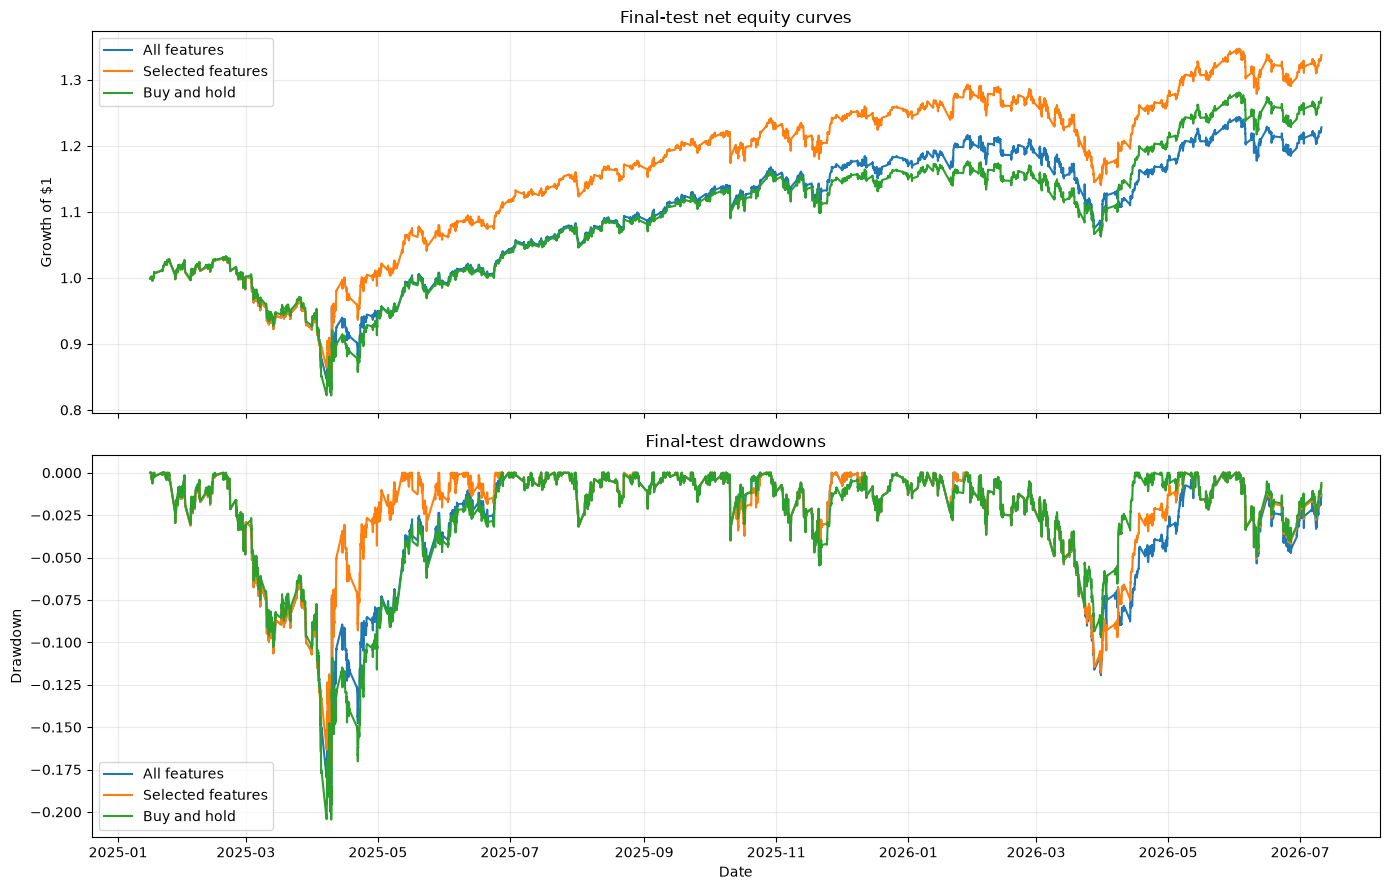

,model,annualized_sharpe,max_drawdown,hit_rate,short_bar_return_contribution
0,All features,0.557873,-0.183389,0.521966,-0.017996
1,Selected features,0.789940,-0.172761,0.523144,0.024679
2,Buy and hold,0.655577,-0.204531,0.522976,0.000000


In [17]:
def strategy_path(predictions, realized_log_returns):
    positions = np.where(np.asarray(predictions) == 1, 1.0, -1.0)
    turnover = np.abs(np.diff(positions, prepend=0.0))
    net_log_returns = positions * np.asarray(realized_log_returns) - turnover * feature_search_cost
    equity = np.exp(np.cumsum(net_log_returns))
    drawdown = equity / np.maximum.accumulate(equity) - 1.0
    return equity, drawdown, net_log_returns, positions

strategy_predictions = {
    'All features': all_feature_test_predictions,
    'Selected features': selected_test_predictions,
    'Buy and hold': buy_hold_predictions,
}
strategy_paths = {
    name: strategy_path(predictions, y_feature_test)
    for name, predictions in strategy_predictions.items()
}
test_datetimes = final_data_with_time['datetime'].to_numpy()[feature_search_validation_end:]

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
for name, (equity, drawdown, _, _) in strategy_paths.items():
    axes[0].plot(test_datetimes, equity, label=name)
    axes[1].plot(test_datetimes, drawdown, label=name)
axes[0].set(title='Final-test net equity curves', ylabel='Growth of $1')
axes[1].set(title='Final-test drawdowns', ylabel='Drawdown', xlabel='Date')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

risk_rows = []
for name, (_, drawdown, net_returns, positions) in strategy_paths.items():
    return_std = net_returns.std(ddof=1)
    risk_rows.append({
        'model': name,
        'annualized_sharpe': net_returns.mean() / return_std * np.sqrt(BARS_PER_YEAR),
        'max_drawdown': drawdown.min(),
        'hit_rate': np.mean(net_returns > 0),
        'short_bar_return_contribution': net_returns[positions < 0].sum(),
    })
display(pd.DataFrame(risk_rows))

## 11. Classification diagnostics

Direction accuracy alone does not describe how the strategy behaves. The confusion matrices, probability distribution, and exposure chart show how rarely the model departs from its predominantly long position.

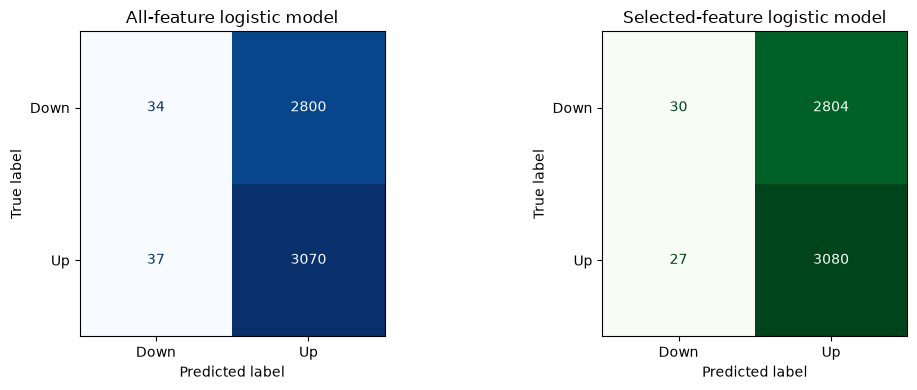

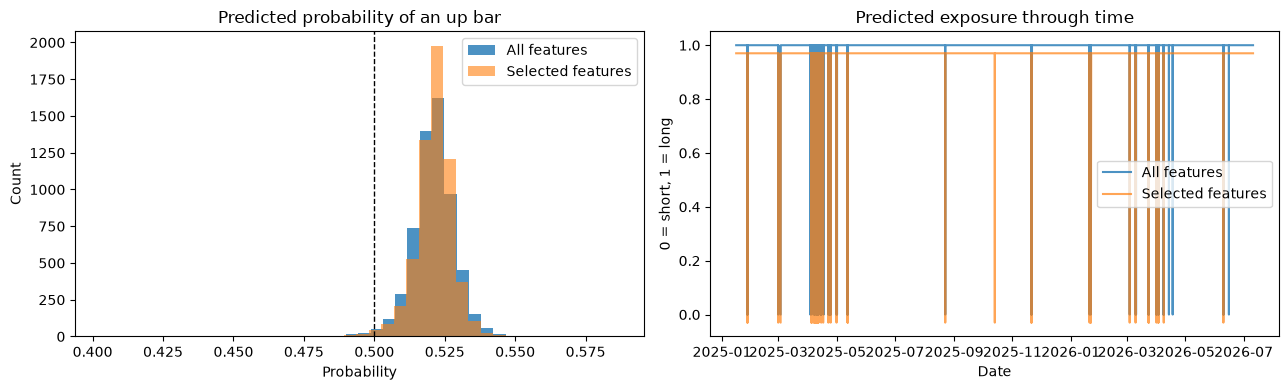

In [18]:
actual_direction = (y_feature_test > 0).astype(np.int8)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    actual_direction, all_feature_test_predictions,
    display_labels=['Down', 'Up'], cmap='Blues', ax=axes[0], colorbar=False,
)
axes[0].set_title('All-feature logistic model')
ConfusionMatrixDisplay.from_predictions(
    actual_direction, selected_test_predictions,
    display_labels=['Down', 'Up'], cmap='Greens', ax=axes[1], colorbar=False,
)
axes[1].set_title('Selected-feature logistic model')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(all_feature_test_probabilities, bins=40, alpha=0.8, label='All features')
axes[0].hist(selected_test_probabilities, bins=40, alpha=0.6, label='Selected features')
axes[0].axvline(0.5, color='black', linestyle='--', linewidth=1)
axes[0].set(title='Predicted probability of an up bar', xlabel='Probability', ylabel='Count')
axes[0].legend()
axes[1].plot(test_datetimes, all_feature_test_predictions, label='All features', alpha=0.8)
axes[1].plot(test_datetimes, selected_test_predictions - 0.03, label='Selected features', alpha=0.7)
axes[1].set(title='Predicted exposure through time', xlabel='Date', ylabel='0 = short, 1 = long')
axes[1].legend()
plt.tight_layout()
plt.show()

## 12. What the original cached experiment actually shows

The seven-feature logistic model returned **33.74% net**, versus **27.30%** for buy-and-hold and **22.80%** for the all-feature model under the original 1-bp turnover accounting. The selected model's validation return was **40.98%**. These are the saved numbers reproduced from the exact processed matrix and matching SQLite search ID; the earlier 43.30%/31.17%/26.60% narrative was stale.

The models are long for roughly 99% of test bars, so market exposure explains much of their positive return. Their small direction-accuracy difference versus always-long does not establish a broad forecasting advantage. The 16,383-subset search still creates selection risk; neither a validation-to-test return change nor the stale prose establishes which model generalizes best.

The original calculations below use negative log returns for shorts, idealized prior-close entries and eight bars as a day. The supplied extended-hours data actually has a median 16 bars per New York session. The following audit preserves the original result for comparison, measures the repairs individually, and recomputes risk from New York daily portfolio returns.

## 13. Controlled repair audit on the original test timestamps

This section is executable independently of the earlier Polars cells. It uses only the supplied Parquet snapshots and read-only SQLite winner. The exact feature matrix/hash and original predictions are reproduced first. Source code, runtime, configuration and input hashes invalidate stale audit results. The historical 16,383-subset search is **not** rerun.

All controlled variants use the **same 5,941 hourly test timestamps**, January 15, 2025 through July 10, 2026. The original seven-feature architecture remains frozen for mechanical comparisons; changing its formulas does not magically make that architecture an independently validated winner.

- **A:** original sign-times-log-return accounting, as a reproduction control.
- **B:** a cash-and-shares ledger, exact executed-dollar costs if enabled, and final liquidation. Shares stay fixed until the position side changes; shorts no longer earn reciprocal-price returns or receive free hourly rebalancing.
- **C:** keep those forecasts but execute changes at the next observed open. Existing positions earn gaps before a change; a new position does not receive a pre-entry gap. Historical opens are idealized fills, not quote-level execution evidence.
- **C2:** refit with the same old windows and a strict label-availability cutoff; this isolates the boundary purge from subsequent feature changes.
- **D:** replace the 8/80-bar day proxies with actual New York-session windows. Each window ends at a completed bar and starts at the same local clock time one or ten observed sessions earlier. Weekends, DST and missing hourly observations no longer imply a fixed number of rows. Preserve the original double-SMA true-range PGO variant to avoid confounding smoothing and window changes.
- **E:** refit using open-to-close direction labels, excluding the already-realized pre-entry gap from the current intrabar label.
- **E2:** refit using open-to-following-open labels, matching the interval between position-change opportunities. A label is available only at that following open; the final prediction need not have a known future label to be marked/liquidated at the dataset endpoint.
- **F:** one additional observed-bar signal delay with the intrabar model, as a separate latency sensitivity rather than a model chosen from its test profit.

Zero costs are the base case. The original 1-bp assumption is a labeled sensitivity, not a measured broker commission. Sharpe is recomputed from New York daily arithmetic portfolio returns at sqrt(252), not by assuming eight independent hourly bars per day. Dividends, stock-borrow fees, margin constraints and quote-level spreads remain unmodeled.

cost_bps                                            return_zero_cost_pct  return_1bp_pct
repair                         model                                                    
A Original calculation         all 14                              25.74           22.80
                               buy and hold                        27.31           27.30
                               selected 7                          36.18           33.74
B Cash/share accounting        all 14                              25.52           22.57
                               buy and hold                        27.31           27.28
                               selected 7                          35.91           33.46
C Next-open fills              all 14                              22.84           19.95
                               buy and hold                        27.31           27.28
                               selected 7                          32.88           30.48
C2 Strict label cutoff         all 14                              22.84           19.95
                               buy and hold                        27.31           27.28
                               selected 7                          32.85           30.41
D Actual-session windows       all 14                              42.32           36.39
                               buy and hold                        27.31           27.28
                               selected 7                          48.69           45.49
E Intrabar target              all 14                              30.74           19.32
                               buy and hold                        27.31           27.28
                               selected 7                          38.00           33.84
E2 Holding-period target       all 14                              19.97           13.50
                               buy and hold                        27.31           27.28
                               selected 7                          26.99           24.25
F Extra-bar delay (intrabar)   all 14                              43.34           30.25
                               buy and hold                        27.31           27.28
                               selected 7                          50.45           45.39
G Quarterly intrabar selection buy and hold                        27.31           27.28
                               past-only selection                 21.13           18.19
H Quarterly holding selection  buy and hold                        27.31           27.28
                               past-only selection                 10.93            8.49

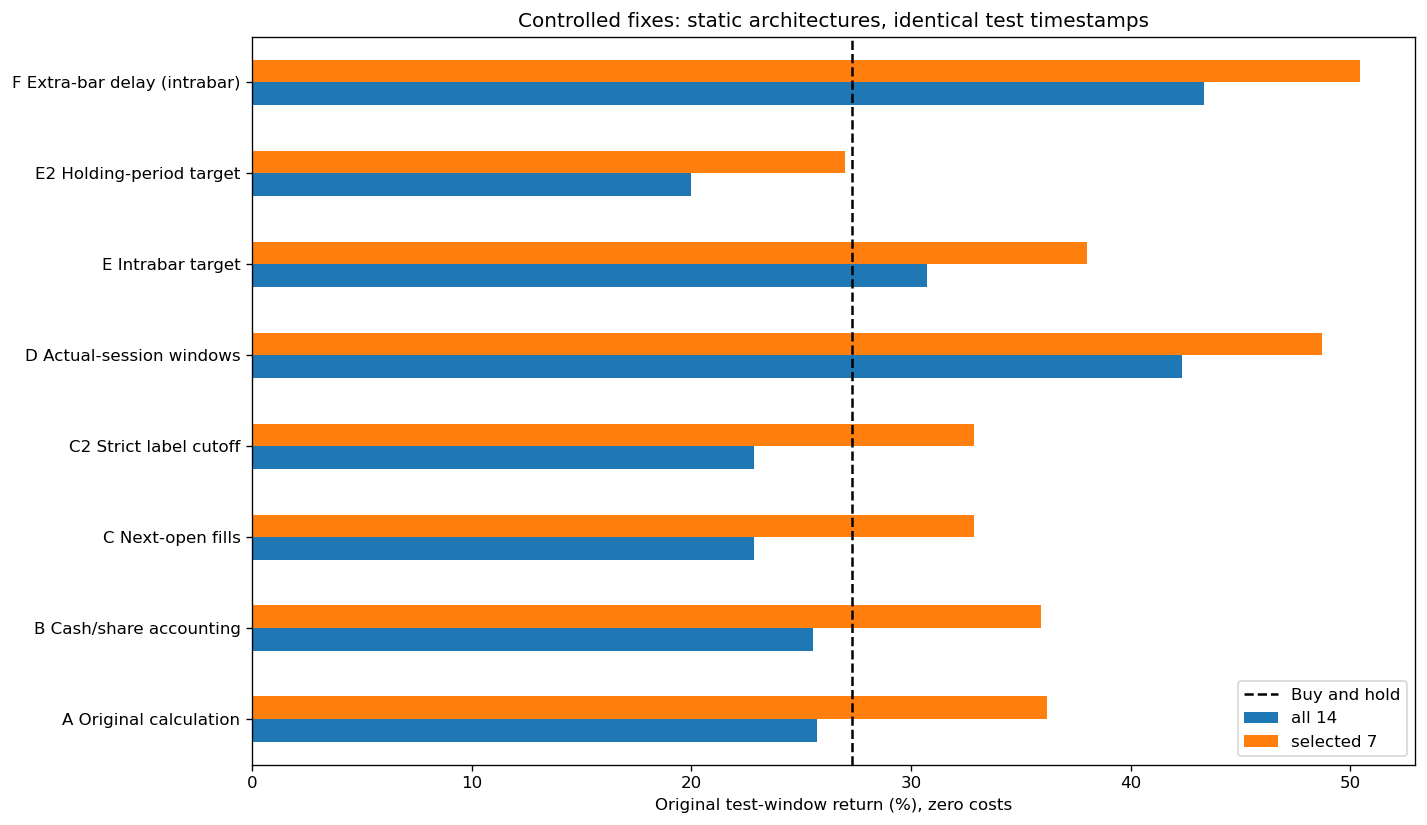

In [19]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from spy_hourly_audit import AuditConfig, audit_fingerprint, run_audit

SPY_AUDIT_ROOT = Path.cwd()
SPY_AUDIT_DATA = SPY_AUDIT_ROOT / "data"
SPY_AUDIT_OUTPUT = SPY_AUDIT_ROOT / "artifacts" / "spy_hourly_audit"
SPY_AUDIT_CONFIG = AuditConfig(cost_bps=0.0, sensitivity_cost_bps=1.0)
REBUILD_SPY_AUDIT = False
spy_audit_report_path = SPY_AUDIT_OUTPUT / "audit_report.json"
spy_audit_report = (
    json.loads(spy_audit_report_path.read_text())
    if spy_audit_report_path.exists()
    else None
)
if (
    REBUILD_SPY_AUDIT
    or spy_audit_report is None
    or spy_audit_report.get("fingerprint")
    != audit_fingerprint(SPY_AUDIT_DATA, SPY_AUDIT_CONFIG)
):
    spy_audit_report = run_audit(SPY_AUDIT_DATA, SPY_AUDIT_OUTPUT, SPY_AUDIT_CONFIG)
spy_controlled = pd.read_csv(SPY_AUDIT_OUTPUT / "controlled_results.csv")
spy_paths = pd.read_csv(
    SPY_AUDIT_OUTPUT / "controlled_paths.csv", parse_dates=["datetime"]
)
spy_stage_names = {
    "A original log accounting": "A Original calculation",
    "B cash/share accounting": "B Cash/share accounting",
    "C next-open fills; same forecasts": "C Next-open fills",
    "C2 strict cutoff; legacy windows": "C2 Strict label cutoff",
    "D session windows + strict label cutoff": "D Actual-session windows",
    "E intrabar target + session windows": "E Intrabar target",
    "E2 next-open holding-period target": "E2 Holding-period target",
    "F extra observed-bar signal delay": "F Extra-bar delay (intrabar)",
    "G nested quarterly selection": "G Quarterly intrabar selection",
    "H nested selection; holding-period target": "H Quarterly holding selection",
}
spy_controlled["repair"] = spy_controlled["stage"].map(spy_stage_names)
spy_control_table = spy_controlled.pivot(
    index=["repair", "model"], columns="cost_bps", values="return"
)
spy_control_table = (100 * spy_control_table).rename(
    columns={0.0: "return_zero_cost_pct", 1.0: "return_1bp_pct"}
)
display(spy_control_table.round(2))
spy_zero = spy_controlled.loc[spy_controlled["cost_bps"].eq(0)]
spy_zero_static = spy_zero.loc[spy_zero["model"].isin(["selected 7", "all 14"])]
spy_zero_static.pivot(index="repair", columns="model", values="return").mul(
    100
).plot.barh(figsize=(12, 7))
plt.axvline(
    100 * spy_zero.loc[spy_zero["model"].eq("buy and hold"), "return"].iloc[0],
    color="black",
    linestyle="--",
    label="Buy and hold",
)
plt.xlabel("Original test-window return (%), zero costs")
plt.ylabel("")
plt.title("Controlled fixes: static architectures, identical test timestamps")
plt.legend()
plt.tight_layout()
plt.show()


### Interpretation of the controlled fixes

For the frozen seven-feature architecture, zero-cost return changes from **36.18%** under original log accounting to **35.91%** with cash/share accounting and **32.88%** with next-open execution. The strict-label-cutoff control is **32.85%**. Correcting the session windows changes the static result to **48.69%**; using intrabar labels gives **38.00%**, while the holding-period-aligned label gives **26.99%**, versus **27.31%** for buy-and-hold. The extra-observed-bar-delay sensitivity returns **50.45%** with intrabar labels. None of these was selected for promotion based on this table.

These results are not a monotone sequence of “bug fixes make returns lower.” Accounting/timing repairs reduce the frozen result, but changing feature windows and target definitions can move fitted decisions in either direction. In particular, the largest static number is not evidence that it is the best model: every variant uses an already-inspected test period and a feature architecture originally chosen under different formulas. The earlier quick arithmetic-short estimate (~33.40% at 1 bp) also used a different constant-dollar rebalancing convention; the explicitly self-financing share ledger gives **33.46%** at the prior close.

At 1 bp, the original reproduced seven-feature return is **33.74%**; cash/share accounting gives **33.46%**, next-open fills **30.48%**, and actual-session windows **45.49%**. These sensitivities do not change the zero-cost base case.

## 14. Corrected chronological re-selection

Mechanical repairs cannot undo the earlier test inspection. This separate retrospective experiment evaluates a **selection procedure**, with quarterly New York cutoffs from 2020 through July 2026. Every quarter uses only earlier completed prices. The last 126 observed New York sessions select among nine prespecified logistic candidates (indicator-only, lag-only or all 14 features, each at C in {0.1, 1, 10}) and buy-and-hold. Scaling/model fitting uses only labels available before inner validation; the winner is refit only on labels available before the outer quarter. Ties prefer buy-and-hold. The objective is validation portfolio return under the same ledger and zero-cost assumption.

The original seven-feature winner is not supplied to this rolling selection: doing so would import a subset chosen using later validation outcomes into earlier years. Two target definitions are evaluated separately: intrabar open-to-close and the full open-to-following-open holding period. Overnight labels do not enter a refit until their next opening price is known. Model decisions are combined first and backtested as one continuous book, so quarterly boundaries do not reset capital or create artificial free liquidations.

This repairs mechanical chronology and limits the search relative to 16,383 subsets. It does not create a fresh untouched period or establish live tradability. The raw snapshots, processed matrix and SQLite checkpoint are unchanged, and all audit outputs are git-ignored.

,model,cost_bps,return,daily_sharpe,max_drawdown,long_rate
0,intrabar-label selection,0.0,0.420964,0.369326,-0.389816,0.924391
1,holding-label selection,0.0,1.620748,0.846818,-0.330558,0.957991
2,buy and hold,0.0,1.335095,0.754173,-0.350038,1.000000
3,intrabar-label selection,1.0,0.000676,0.099538,-0.480808,0.924391
4,holding-label selection,1.0,0.938789,0.615276,-0.354407,0.957991
5,buy and hold,1.0,1.334628,0.754020,-0.350038,1.000000


,quarter,choice,C,columns,validation_return,last_inner_training_completion,validation_start,last_refit_completion,outer_start,target
42,2023Q4,indicators,0.1,"ma_distance, upper_relative, lower_relative, p...",0.068365,2023-03-30 23:00:00+00:00,2023-03-31 08:00:00+00:00,2023-09-29 23:00:00+00:00,2023-10-02 08:00:00+00:00,return_oo
43,2024Q1,buy and hold,NaN,NaN,0.071184,2023-06-30 23:00:00+00:00,2023-07-03 08:00:00+00:00,2023-12-30 00:00:00+00:00,2024-01-02 09:00:00+00:00,return_oo
44,2024Q2,buy and hold,NaN,NaN,0.226776,2023-09-27 23:00:00+00:00,2023-09-28 08:00:00+00:00,2024-03-28 23:00:00+00:00,2024-04-01 08:00:00+00:00,return_oo
45,2024Q3,buy and hold,NaN,NaN,0.142693,2023-12-28 00:00:00+00:00,2023-12-28 09:00:00+00:00,2024-06-28 23:00:00+00:00,2024-07-01 08:00:00+00:00,return_oo
46,2024Q4,buy and hold,NaN,NaN,0.098603,2024-04-01 23:00:00+00:00,2024-04-02 08:00:00+00:00,2024-09-30 23:00:00+00:00,2024-10-01 08:00:00+00:00,return_oo
47,2025Q1,lags,0.1,"return_lag_1, return_lag_2, return_lag_3, retu...",0.083399,2024-07-02 23:00:00+00:00,2024-07-03 08:00:00+00:00,2025-01-01 00:00:00+00:00,2025-01-02 09:00:00+00:00,return_oo
48,2025Q2,lags,0.1,"return_lag_1, return_lag_2, return_lag_3, retu...",-0.022063,2024-09-26 23:00:00+00:00,2024-09-27 08:00:00+00:00,2025-03-31 23:00:00+00:00,2025-04-01 08:00:00+00:00,return_oo
49,2025Q3,indicators,0.1,"ma_distance, upper_relative, lower_relative, p...",0.078249,2024-12-24 21:00:00+00:00,2024-12-26 09:00:00+00:00,2025-06-30 23:00:00+00:00,2025-07-01 08:00:00+00:00,return_oo
50,2025Q4,indicators,0.1,"ma_distance, upper_relative, lower_relative, p...",0.272321,2025-03-31 23:00:00+00:00,2025-04-01 08:00:00+00:00,2025-09-30 23:00:00+00:00,2025-10-01 08:00:00+00:00,return_oo
51,2026Q1,buy and hold,NaN,NaN,0.098645,2025-07-03 00:00:00+00:00,2025-07-03 08:00:00+00:00,2026-01-01 00:00:00+00:00,2026-01-02 09:00:00+00:00,return_oo


model,buy and hold,holding-label selection,intrabar-label selection
year,,,
2020,15.72,81.93,-15.05
2021,26.91,21.22,24.53
2022,-19.37,-25.06,-11.69
2023,24.01,13.09,9.58
2024,23.46,23.46,13.25
2025,16.37,2.61,11.60
2026,10.69,10.69,9.82


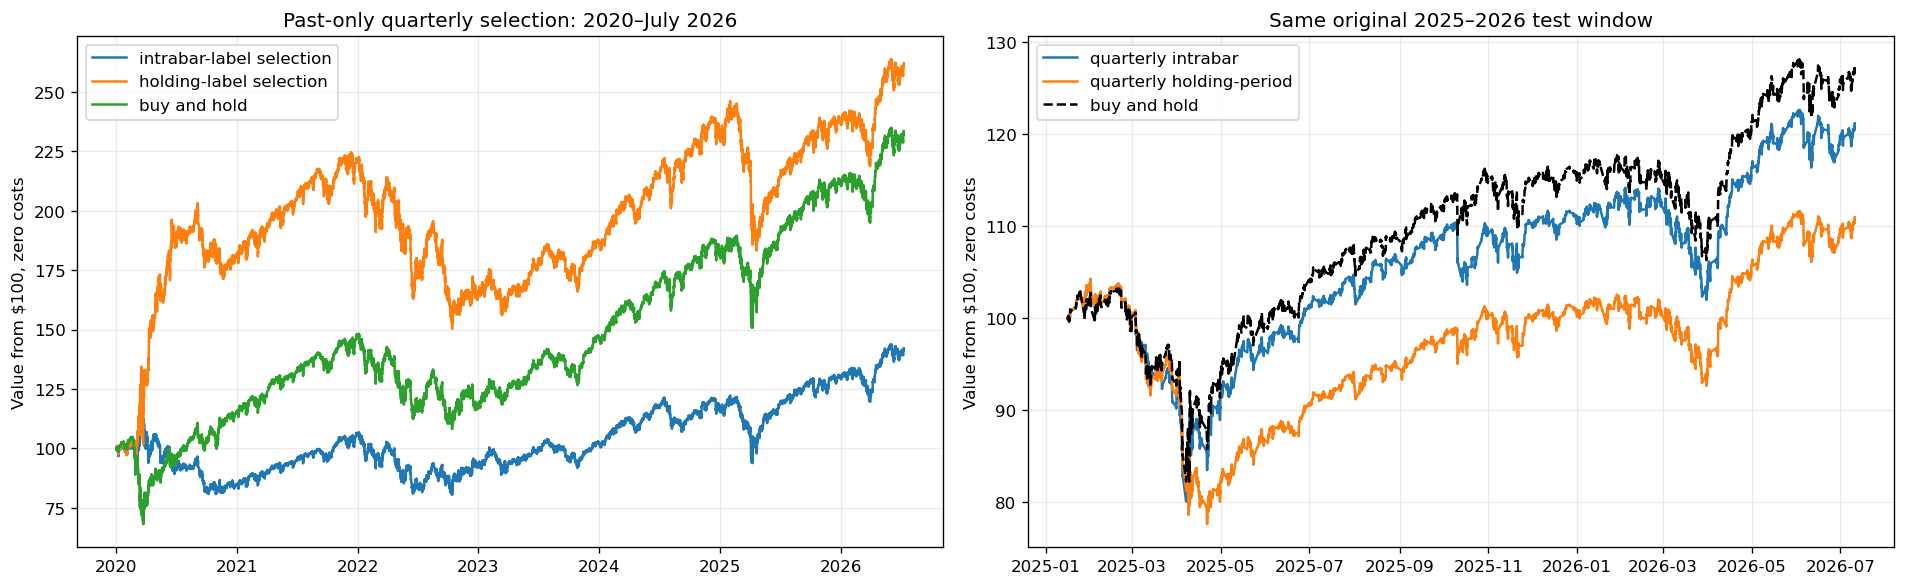

In [20]:
spy_walk_results = pd.read_csv(SPY_AUDIT_OUTPUT / "walk_forward_results.csv")
spy_walk_paths = pd.read_csv(
    SPY_AUDIT_OUTPUT / "walk_forward_paths.csv", parse_dates=["datetime"]
)
spy_walk_audit = pd.read_csv(
    SPY_AUDIT_OUTPUT / "walk_forward_audit.csv",
    parse_dates=[
        "last_inner_training_completion",
        "validation_start",
        "last_refit_completion",
        "outer_start",
    ],
)
assert (
    spy_walk_audit["last_inner_training_completion"]
    .lt(spy_walk_audit["validation_start"])
    .all()
)
assert spy_walk_audit["last_refit_completion"].lt(spy_walk_audit["outer_start"]).all()
assert (
    audit_fingerprint(SPY_AUDIT_DATA, SPY_AUDIT_CONFIG)
    == spy_audit_report["fingerprint"]
)
display(
    spy_walk_results[
        ["model", "cost_bps", "return", "daily_sharpe", "max_drawdown", "long_rate"]
    ]
)
display(spy_walk_audit.tail(12))
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for model_name, group in spy_walk_paths.loc[spy_walk_paths["cost_bps"].eq(0)].groupby(
    "model", sort=False
):
    axes[0].plot(group["datetime"], 100 * group["equity"], label=model_name)
axes[0].set(
    title="Past-only quarterly selection: 2020–July 2026",
    ylabel="Value from $100, zero costs",
)
axes[0].legend()
for model_name, stage in [
    ("quarterly intrabar", "G nested quarterly selection"),
    ("quarterly holding-period", "H nested selection; holding-period target"),
]:
    group = spy_paths.loc[
        spy_paths["stage"].eq(stage)
        & spy_paths["model"].eq("past-only selection")
        & spy_paths["cost_bps"].eq(0)
    ]
    axes[1].plot(group["datetime"], 100 * group["equity"], label=model_name)
benchmark = spy_paths.loc[
    spy_paths["stage"].eq("H nested selection; holding-period target")
    & spy_paths["model"].eq("buy and hold")
    & spy_paths["cost_bps"].eq(0)
]
axes[1].plot(
    benchmark["datetime"],
    100 * benchmark["equity"],
    label="buy and hold",
    color="black",
    linestyle="--",
)
axes[1].set(
    title="Same original 2025–2026 test window", ylabel="Value from $100, zero costs"
)
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
spy_annual = spy_walk_paths.loc[spy_walk_paths["cost_bps"].eq(0)].copy()
spy_annual["year"] = spy_annual["datetime"].dt.tz_convert("America/New_York").dt.year
spy_annual_table = (
    spy_annual.groupby(["year", "model"])["net_return"]
    .apply(lambda values: (1 + values).prod() - 1)
    .unstack("model")
)
display((100 * spy_annual_table).round(2))


### What survives the repairs

On the original 2025–2026 test timestamps, quarterly past-only selection returns **21.13%** with intrabar labels and **10.93%** with holding-period labels, versus **27.31%** for buy-and-hold at zero costs. The highest static variants therefore do not translate into a consistent win for chronological re-selection in that period.

Over the wider 2020–July 2026 walk-forward run, holding-period-aligned selection returns **162.07%**, versus **133.51%** for buy-and-hold; daily Sharpe is **0.847 versus 0.754** and maximum drawdown **−33.06% versus −35.00%**. It remains long **95.80%** of bars. The intrabar-label version returns **42.10%** over that wider span. These are distinct target/selection procedures, not a test-based instruction to pick whichever curve wins.

The 1-bp sensitivity reverses the holding-period strategy's wider-period advantage: **93.88%**, versus **133.46%** for buy-and-hold. Zero costs remain the requested base case. This demonstrates sensitivity, not an assertion that a commission-free broker charges that amount.

The investigation supports correcting the bookkeeping, timing, label clocks and feature windows. It does not support presenting the stale 43.30% headline or the best static corrected variant as a proven trading edge. All comparisons are price-only, omit dividends/borrow/funding, and assume executable observed opens despite extended-hours liquidity and signal-computation latency. A start-of-bar label is not itself proof that its opening trade was obtainable after processing the prior bar; the extra-bar-delay case is provided to expose that sensitivity.

Fourteen focused tests pass, covering independent window arithmetic, DST/weekend/missing-hour boundaries, future-price mutation, fixed-share shorts, gap attribution, exact entry/exit costs, daily risk grouping and both intrabar/overnight label-availability cutoffs. The controlled audit reproduces the original cached result, and full input hashes verify that neither Parquet snapshot nor the SQLite checkpoint was modified.

To rerun with the existing environment and cached data:

```sh
uv run --no-project python spy_hourly_audit.py
uv run --no-project python -m unittest -v test_spy_hourly_audit
uv tool run ruff check spy_hourly_audit.py test_spy_hourly_audit.py
```

## 15. Prespecified model improvements using the same cached data

This experiment uses the open-to-following-observed-open direction target, quarterly expanding refits and identical outer timestamps. Zero costs remain the primary case. The candidate procedure **C** and the following rules were fixed before inspecting these new outer results; these are retrospective comparisons, not a new holdout.

| Arm | Change |
| --- | --- |
| A | Reproduce the current one-window return selector |
| B | Replace dollar SMA distance with `(SMA10 - previous_close) / previous_close` |
| C — primary proposed procedure | B plus stable probability/portfolio selection across earlier windows |
| D | C plus known New York hour sin/cos and elapsed time since the previous observed bar |
| E | C plus lagged relative range, closing location, prior opening gap, log-volume and log-dollar-volume surprises |
| F | C plus both context/activity families |
| G | C using one extra completed bar of price/volume information; current clock stays known |

A/B use the earlier 126-session return selector. C–G compare the same three feature pools and three C penalties on **three preceding, nonoverlapping 63-session validation windows**, fitting each from expanding earlier history. A candidate must improve average daily log loss over its training-only class-prior forecast, improve that score in at least two folds, and beat buy-and-hold daily log returns in at least two folds. Among qualifying models within one standard error of the best probability improvement, prefer fewer features and stronger regularization. No qualifying model means buy-and-hold for the binary trading rules.

Indicators and activity features are lagged; the clock is known at prediction time. Volume surprises use one-session centered log1p values. PGO smoothing is preserved. All inner probability labels must be known strictly before their fold ends; fitting labels must be known strictly before validation/refit begins.

For A and C, compare long/short and long/cash at 0.5 with a confidence policy that can hold cash. The confidence half-width is chosen only from earlier validation among 0, 0.025 and 0.05 using average daily log return. If no model qualifies, the confidence policy holds cash. This fallback distinction is explicit: a difference can come from choosing market exposure versus cash, not better forecasts.

The saved probability, Brier and calibration diagnostics compare against a constant positive-class frequency fitted on each quarter's training data. No post-hoc probability calibrator has been fitted. [Scikit-learn's calibration documentation](https://scikit-learn.org/stable/modules/calibration.html) explains why log loss and Brier assess more than calibration alone.


In [21]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from spy_hourly_research import PRIMARY, ResearchConfig, run_study, study_fingerprint

SPY_RESEARCH_CONFIG = ResearchConfig()
SPY_RESEARCH_OUTPUT = Path("artifacts/spy_hourly_research")
SPY_RESEARCH_REPORT = SPY_RESEARCH_OUTPUT / "research_report.json"
REBUILD_SPY_RESEARCH = False
spy_research_report = (
    json.loads(SPY_RESEARCH_REPORT.read_text())
    if SPY_RESEARCH_REPORT.exists()
    else None
)
if (
    REBUILD_SPY_RESEARCH
    or spy_research_report is None
    or spy_research_report.get("fingerprint")
    != study_fingerprint("data", SPY_RESEARCH_CONFIG)
):
    spy_research_report = run_study(config=SPY_RESEARCH_CONFIG)
spy_research_portfolio = pd.read_csv(SPY_RESEARCH_OUTPUT / "portfolio_results.csv")
spy_research_scores = pd.read_csv(SPY_RESEARCH_OUTPUT / "probability_scores.csv")
spy_research_probabilities = pd.read_csv(
    SPY_RESEARCH_OUTPUT / "probabilities.csv", parse_dates=["datetime"]
)
spy_research_paths = pd.read_csv(
    SPY_RESEARCH_OUTPUT / "paths.csv", parse_dates=["datetime"]
)
spy_research_zero = spy_research_portfolio.loc[spy_research_portfolio["cost_bps"].eq(0)]
spy_research_main = spy_research_zero.loc[spy_research_zero["policy"].eq("long_short")]
display(
    spy_research_main.pivot(index="stage", columns="span", values="return")
    .mul(100)
    .round(2)
)
display(
    spy_research_scores[
        [
            "span",
            "stage",
            "log_loss",
            "prior_log_loss",
            "log_loss_gain",
            "brier_gain",
            "accuracy",
            "auc",
        ]
    ].round(6)
)


span,2020 onward,original test
stage,,
A current,162.07,10.93
B normalize only,163.67,4.89
C stable normalized,104.79,19.20
D clock,209.93,27.31
E activity,124.17,25.25
F combined,120.29,21.23
G extra-bar delay,85.87,28.98
buy and hold,133.51,27.31


,span,stage,log_loss,prior_log_loss,log_loss_gain,brier_gain,accuracy,auc
0,2020 onward,A current,0.692403,0.691833,-0.000569,-0.000223,0.524342,0.503203
1,2020 onward,B normalize only,0.692432,0.691833,-0.000598,-0.000238,0.524381,0.503218
2,2020 onward,C stable normalized,0.692570,0.691833,-0.000737,-0.000309,0.524844,0.496228
3,2020 onward,D clock,0.692526,0.691833,-0.000692,-0.000287,0.526001,0.491715
4,2020 onward,E activity,0.692581,0.691833,-0.000747,-0.000310,0.525654,0.495257
5,2020 onward,F combined,0.691794,0.691833,0.000039,0.000019,0.526811,0.495464
6,2020 onward,G extra-bar delay,0.692759,0.691833,-0.000926,-0.000388,0.525384,0.490445
7,original test,A current,0.692174,0.692215,0.000041,0.000022,0.519192,0.508686
8,original test,B normalize only,0.692286,0.692215,-0.000072,-0.000034,0.518350,0.506240
9,original test,C stable normalized,0.692095,0.692215,0.000119,0.000059,0.521549,0.505263


## 16. Predictive skill, calibration and economic uncertainty

Positive log-loss/Brier gains mean improvement over the quarter's training-only constant prior. The score table includes fallback quarters, whose prior forecasts correctly have zero gain. Unavailable final next-open labels are excluded from forecast scoring but the final close can still mark portfolio equity. Calibration uses fixed probability bins and includes their observation counts.

Zero-cost portfolio results include long/cash and confidence decisions, average daily excess return with a paired **20-session moving-block bootstrap** (1,000 draws), and a regression on daily SPY returns. The beta-matched benchmark scales daily SPY returns using an **ex-post fitted beta**, making it a descriptive risk comparison rather than a tradable historical strategy. Alpha is a descriptive regression intercept, not a significance claim. Bootstrap intervals condition on the generated predictions, do not repeat model selection and do not correct for the seven-arm comparison.

The extra-bar-delay arm retrains with older information; it does not shift already selected future decisions. Historic observed opens remain idealized execution prices, and dividends/borrow/funding/spread/impact are omitted. The original test panel starts with a fresh account at its opening price for every arm, matching the earlier repair audit.


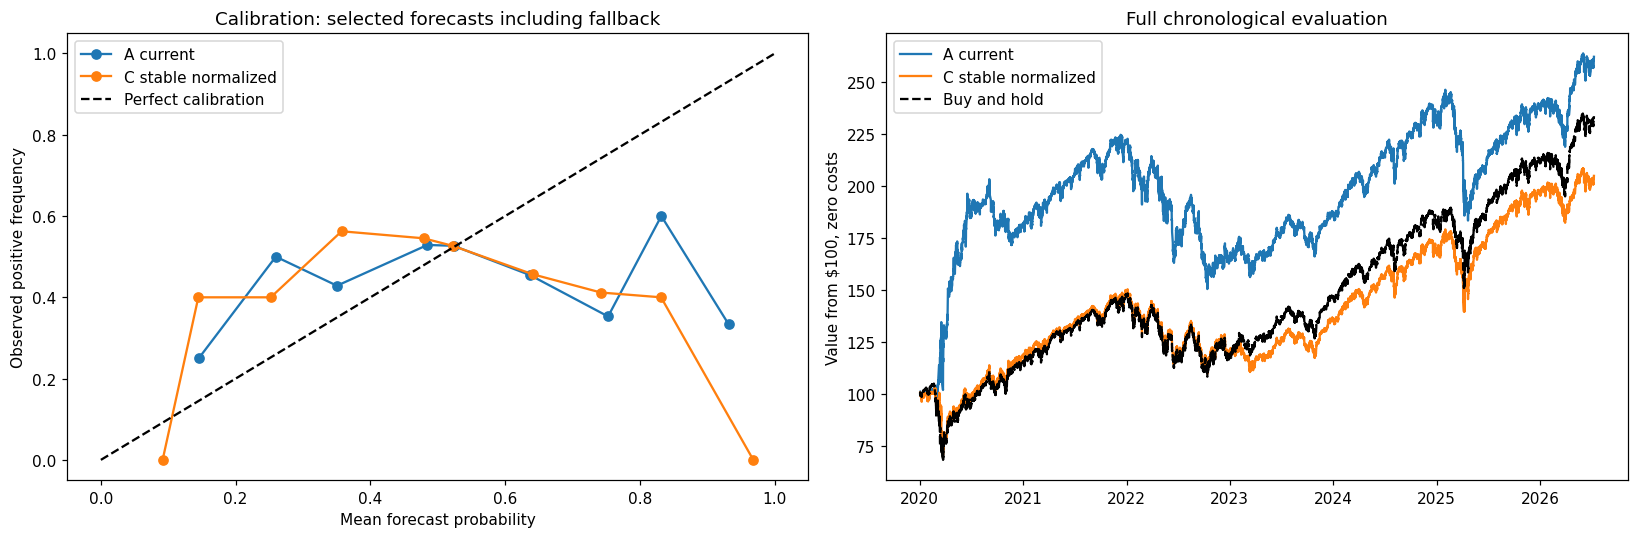

,stage,source,bin,count,mean_probability,observed_frequency
0,A current,probability,1,4,0.145286,0.250000
1,A current,probability,2,10,0.259620,0.500000
2,A current,probability,3,35,0.350383,0.428571
3,A current,probability,4,1040,0.484596,0.528846
4,A current,probability,5,24742,0.523449,0.526797
5,A current,probability,6,66,0.637105,0.454545
6,A current,probability,7,17,0.752699,0.352941
7,A current,probability,8,5,0.831720,0.600000
8,A current,probability,9,3,0.931720,0.333333
9,A current,prior,5,25922,0.522235,0.526387


,span,stage,policy,return,long_rate,cash_rate,beta,alpha_daily_bps,excess_daily_bps,excess_daily_bps_ci_low,excess_daily_bps_ci_high,expost_beta_matched_market_return
1,2020 onward,A current,long_short,1.6207,0.9580,0.0000,0.7134,2.4016,0.6917,-4.3972,7.2941,0.8804
3,2020 onward,A current,long_cash,1.5242,0.9580,0.0420,0.8574,1.2096,0.3585,-2.1931,3.6717,1.1020
5,2020 onward,A current,confidence,1.0017,0.4885,0.4805,0.3924,2.3573,-1.2682,-6.7881,5.3476,0.4385
9,2020 onward,C stable normalized,long_short,1.0479,0.9807,0.0000,0.7531,0.6449,-0.8285,-2.3817,1.1728,0.9400
11,2020 onward,C stable normalized,long_cash,1.2161,0.9807,0.0193,0.8776,0.3068,-0.4235,-1.1981,0.5827,1.1343
13,2020 onward,C stable normalized,confidence,-0.0943,0.1620,0.8237,0.0686,-0.7860,-6.3432,-10.9257,-1.4346,0.0687
24,original test,A current,long_short,0.1093,0.9892,0.0000,0.8385,-2.6752,-3.8294,-11.1820,0.0238,0.2284
26,original test,A current,long_cash,0.1893,0.9892,0.0108,0.9191,-1.3343,-1.9124,-5.5846,0.0118,0.2507
28,original test,A current,confidence,0.1372,0.4136,0.5841,0.3936,0.8610,-3.4739,-12.5194,6.1458,0.1061
32,original test,C stable normalized,long_short,0.1920,0.9852,0.0000,0.9696,-1.5689,-1.7860,-5.1246,0.2366,0.2647


,span,stage,policy,return,max_drawdown
2,2020 onward,A current,long_short,0.9388,-0.3544
4,2020 onward,A current,long_cash,1.1709,-0.3058
6,2020 onward,A current,confidence,0.4749,-0.2768
8,2020 onward,B normalize only,long_short,0.9631,-0.3475
10,2020 onward,C stable normalized,long_short,0.8116,-0.3442
12,2020 onward,C stable normalized,long_cash,1.0841,-0.3189
14,2020 onward,C stable normalized,confidence,-0.2678,-0.3442
16,2020 onward,D clock,long_short,1.8605,-0.2706
18,2020 onward,E activity,long_short,0.9918,-0.3617
20,2020 onward,F combined,long_short,1.0975,-0.3500


In [22]:
spy_research_calibration = pd.read_csv(SPY_RESEARCH_OUTPUT / "calibration.csv")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for stage in ["A current", PRIMARY]:
    selected = spy_research_calibration.loc[
        spy_research_calibration["stage"].eq(stage)
        & spy_research_calibration["source"].eq("probability")
    ]
    axes[0].plot(
        selected["mean_probability"],
        selected["observed_frequency"],
        marker="o",
        label=stage,
    )
    selected_paths = spy_research_paths.loc[
        spy_research_paths["stage"].eq(stage)
        & spy_research_paths["policy"].eq("long_short")
        & spy_research_paths["cost_bps"].eq(0)
    ]
    axes[1].plot(
        selected_paths["datetime"], 100 * selected_paths["equity"], label=stage
    )
axes[0].plot([0, 1], [0, 1], color="black", linestyle="--", label="Perfect calibration")
axes[0].set(
    xlabel="Mean forecast probability",
    ylabel="Observed positive frequency",
    title="Calibration: selected forecasts including fallback",
)
axes[0].legend()
market_probs = spy_research_probabilities.loc[
    spy_research_probabilities["stage"].eq("A current")
]
from spy_hourly_audit import RAW_NAME

spy_research_raw = pd.read_parquet(Path("data/raw/SPY") / RAW_NAME).sort_values(
    "datetime"
)
spy_research_market = spy_research_raw.loc[
    spy_research_raw["datetime"].isin(market_probs["datetime"])
]
axes[1].plot(
    spy_research_market["datetime"],
    100 * spy_research_market["close"] / spy_research_market["open"].iloc[0],
    color="black",
    linestyle="--",
    label="Buy and hold",
)
axes[1].set(ylabel="Value from $100, zero costs", title="Full chronological evaluation")
axes[1].legend()
plt.tight_layout()
plt.show()
display(
    spy_research_calibration.loc[
        spy_research_calibration["stage"].isin(["A current", PRIMARY])
    ]
)
display(
    spy_research_zero.loc[
        spy_research_zero["stage"].isin(["A current", PRIMARY]),
        [
            "span",
            "stage",
            "policy",
            "return",
            "long_rate",
            "cash_rate",
            "beta",
            "alpha_daily_bps",
            "excess_daily_bps",
            "excess_daily_bps_ci_low",
            "excess_daily_bps_ci_high",
            "expost_beta_matched_market_return",
        ],
    ].round(4)
)
display(
    spy_research_portfolio.loc[
        spy_research_portfolio["cost_bps"].eq(1),
        ["span", "stage", "policy", "return", "max_drawdown"],
    ].round(4)
)


## 17. Selection and reproducibility checks

Every candidate/fold score, selected feature pool, fitted standardized coefficient, training class prior, confidence threshold and label cutoff is saved in `artifacts/spy_hourly_research/`. Coefficients describe conditional associations in fitted models; they are not causal feature effects. The original selected seven are not reused in this study. Reports are reusable only when their code/input/configuration/runtime fingerprints match.

The table below reports selected pools and fallback frequency. Inspecting the full candidate folds explains whether an arm failed the probability gate, economic gate or both. No new arm is automatically promoted because its inspected outer return is the largest.


In [23]:
spy_research_decisions = pd.read_csv(SPY_RESEARCH_OUTPUT / "decisions.csv")
spy_research_folds = pd.read_csv(SPY_RESEARCH_OUTPUT / "validation_folds.csv")
assert (
    pd.to_datetime(spy_research_folds["last_training_label"], utc=True)
    < pd.to_datetime(spy_research_folds["validation_start"], utc=True)
).all()
assert (
    pd.to_datetime(spy_research_folds["last_scored_label"], utc=True)
    < pd.to_datetime(spy_research_folds["validation_end"], utc=True)
).all()
assert (
    pd.to_datetime(spy_research_decisions["last_refit_label"], utc=True)
    < pd.to_datetime(spy_research_decisions["refit_cutoff"], utc=True)
).all()
assert spy_research_probabilities.groupby("stage").size().nunique() == 1
assert spy_research_report["fingerprint"] == study_fingerprint(
    "data", SPY_RESEARCH_CONFIG
)
display(pd.crosstab(spy_research_decisions["stage"], spy_research_decisions["choice"]))
display(
    spy_research_decisions.loc[spy_research_decisions["stage"].eq(PRIMARY)].tail(12)
)
spy_research_annual = pd.read_csv(SPY_RESEARCH_OUTPUT / "annual_returns.csv")
display(
    spy_research_annual.loc[spy_research_annual["policy"].eq("long_short")]
    .pivot(index="year", columns="stage", values="return")
    .mul(100)
    .round(2)
)


choice,all,buy and hold,indicators,lags
stage,,,,
A current,3,9,7,8
B normalize only,3,7,9,8
C stable normalized,6,19,1,1
D clock,1,26,0,0
E activity,4,20,1,2
F combined,4,22,1,0
G extra-bar delay,2,20,4,1


,stage,quarter,choice,C,columns,confidence_band,training_prior,last_refit_label,refit_cutoff,outer_start,train_rows
69,C stable normalized,2023Q4,buy and hold,NaN,NaN,NaN,0.522122,2023-09-29 23:00:00+00:00,2023-10-01 04:00:00+00:00,2023-10-02 08:00:00+00:00,28411
70,C stable normalized,2024Q1,buy and hold,NaN,NaN,NaN,0.521723,2023-12-30 00:00:00+00:00,2024-01-01 05:00:00+00:00,2024-01-02 09:00:00+00:00,29416
71,C stable normalized,2024Q2,buy and hold,NaN,NaN,NaN,0.522357,2024-03-28 23:00:00+00:00,2024-04-01 04:00:00+00:00,2024-04-01 08:00:00+00:00,30393
72,C stable normalized,2024Q3,buy and hold,NaN,NaN,NaN,0.522577,2024-06-28 23:00:00+00:00,2024-07-01 04:00:00+00:00,2024-07-01 08:00:00+00:00,31404
73,C stable normalized,2024Q4,buy and hold,NaN,NaN,NaN,0.523345,2024-09-30 23:00:00+00:00,2024-10-01 04:00:00+00:00,2024-10-01 08:00:00+00:00,32426
74,C stable normalized,2025Q1,lags,0.1,"return_lag_1, return_lag_2, return_lag_3, return_lag_4, return_lag_5, return_lag_6, return_lag_7, return_lag_8",0.000,0.523681,2025-01-01 00:00:00+00:00,2025-01-01 05:00:00+00:00,2025-01-02 09:00:00+00:00,33444
75,C stable normalized,2025Q2,buy and hold,NaN,NaN,NaN,0.522830,2025-03-31 23:00:00+00:00,2025-04-01 04:00:00+00:00,2025-04-01 08:00:00+00:00,34407
76,C stable normalized,2025Q3,all,0.1,"ma_distance_pct, upper_relative, lower_relative, pgo, mean_return_1_session, mean_return_10_sessions, return_lag_1, return_lag_2, return_lag_3, return_lag_4, return_lag_5, return_lag_6, return_lag_7, return_lag_8",0.050,0.522273,2025-06-30 23:00:00+00:00,2025-07-01 04:00:00+00:00,2025-07-01 08:00:00+00:00,35401
77,C stable normalized,2025Q4,all,0.1,"ma_distance_pct, upper_relative, lower_relative, pgo, mean_return_1_session, mean_return_10_sessions, return_lag_1, return_lag_2, return_lag_3, return_lag_4, return_lag_5, return_lag_6, return_lag_7, return_lag_8",0.025,0.522704,2025-09-30 23:00:00+00:00,2025-10-01 04:00:00+00:00,2025-10-01 08:00:00+00:00,36426
78,C stable normalized,2026Q1,all,0.1,"ma_distance_pct, upper_relative, lower_relative, pgo, mean_return_1_session, mean_return_10_sessions, return_lag_1, return_lag_2, return_lag_3, return_lag_4, return_lag_5, return_lag_6, return_lag_7, return_lag_8",0.025,0.522872,2026-01-01 00:00:00+00:00,2026-01-01 05:00:00+00:00,2026-01-02 09:00:00+00:00,37447


stage,A current,B normalize only,C stable normalized,D clock,E activity,F combined,G extra-bar delay
year,,,,,,,
2020,81.93,81.93,18.76,53.60,15.44,15.72,-6.63
2021,21.22,21.49,25.32,26.91,26.91,26.91,23.58
2022,-25.06,-24.95,-19.37,-19.37,-19.37,-19.37,-19.37
2023,13.09,21.74,13.28,24.01,24.01,24.01,24.01
2024,23.46,21.58,23.46,23.46,20.77,22.31,23.46
2025,2.61,2.61,16.60,16.37,19.26,16.30,17.90
2026,10.69,4.67,4.67,10.69,6.26,5.47,10.69


### Measured outcome of the improvement study

The reproduced current selector returns **162.07%**, the prespecified stable normalized procedure **104.79%**, and buy-and-hold **133.51%** over 2020–July 2026 at zero costs. On the original 2025–2026 dates, the stable normalized procedure returns **19.20%** versus **27.31%** for buy-and-hold. Its full-period log-loss gain over the training-prior baseline is **-0.000737** (positive is better).

The stable normalized procedure falls back to buy-and-hold in **19 of 27 quarters**. Its mean daily excess return's paired bootstrap interval is **[-2.382, 1.173] bps**. Read the exposure/cash policy comparisons alongside this result: market participation and predictive skill are different quantities.

The clock arm returns **209.93%** over the full period, but selects a model only in **2020Q1** and falls back to buy-and-hold in the other **26 quarters**. Its recent-period return exactly matches the market. Its full-period excess-return bootstrap interval, **[-0.454, 5.429] bps/day**, includes zero. This is a concentrated historical result, not consistent evidence that the clock features predict better.

The confidence policy's cash fallback is consequential: stable normalized confidence returns **-9.43%** over the full period versus **+121.61%** for stable normalized long/cash and **+133.51%** for buy-and-hold. No threshold was changed in response.

The tables retain every prespecified arm, including worse results. Better accounting, diagnostics and stable selection do not guarantee a higher inspected backtest. Feature-family and delay arms remain experiments; these results do not establish an untouched-period edge. Thirty focused tests pass, including independent sklearn score parity, analytic feature/risk oracles, price-scale invariance, future-data mutation, label availability, policy boundaries and validation-only threshold selection.

Reproduce using `uv run --no-sync python spy_hourly_research.py`; run all tests using `uv run --no-sync python -m unittest discover -v`.
